### Load dataset

 Hugging Face Dataset - https://huggingface.co/datasets/mteb/banking77

In [1]:
# import libraries

from datasets import load_dataset, DatasetDict
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
import numpy as np

from transformers import AutoTokenizer
from transformers import TrainingArguments, Trainer
from transformers import AutoModelForSequenceClassification, DistilBertForSequenceClassification, DistilBertModel
from sklearn.metrics import classification_report

In [2]:
bank_df = load_dataset("mteb/banking77")
bank_df

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/294k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/91.4k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9993 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3076 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 9993
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 3076
    })
})

In [3]:
bank_df['train'][:5]

{'text': ['I am still waiting on my card?',
  "What can I do if my card still hasn't arrived after 2 weeks?",
  'I have been waiting over a week. Is the card still coming?',
  'Can I track my card while it is in the process of delivery?',
  'How do I know if I will get my card, or if it is lost?'],
 'label': [11, 11, 11, 11, 11],
 'label_text': ['card_arrival',
  'card_arrival',
  'card_arrival',
  'card_arrival',
  'card_arrival']}

### Exploratory Analysis

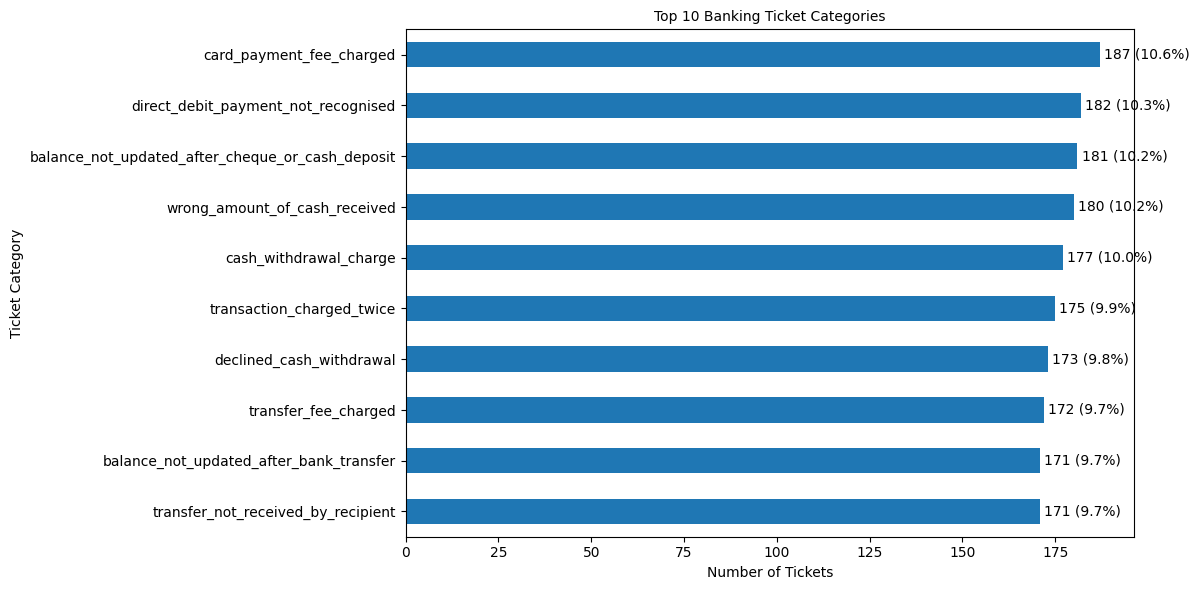

In [4]:
bank_data = pd.DataFrame(bank_df["train"])
top_10 = bank_data['label_text'].value_counts().head(10)

# total for percentage calculation
total = top_10.sum()
plt.figure(figsize=(12, 6))
ax = top_10.plot(kind='barh')

plt.title('Top 10 Banking Ticket Categories', fontsize=10)
plt.xlabel('Number of Tickets')
plt.ylabel('Ticket Category')

# highest count at the top
plt.gca().invert_yaxis()

# count + percentage labels
for container in ax.containers:
    labels = [
        f'{int(value)} ({value/total*100:.1f}%)'
        for value in container.datavalues
    ]
    ax.bar_label(container, labels=labels, padding=3)

plt.tight_layout()
plt.show()

### Tokenization

In [5]:
# load tokenizer
name = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(name)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [6]:
# Prepare the dataset - this tokenizes the dataset in batches of 16 examples.
bank_tokenized = bank_df.map(
    lambda example: tokenizer(example['text'], 
                              padding=True, 
                              truncation=True, 
                              max_length=64), 
    batched=True, batch_size=16
)

bank_tokenized = bank_tokenized.remove_columns(["text", "label_text"])
bank_tokenized = bank_tokenized.rename_column("label", "labels")
bank_tokenized.set_format("torch")

Map:   0%|          | 0/9993 [00:00<?, ? examples/s]

Map:   0%|          | 0/3076 [00:00<?, ? examples/s]

In [7]:
bank_tokenized['train'][0:2]

{'labels': tensor([11, 11]),
 'input_ids': tensor([[ 101, 1045, 2572, 2145, 3403, 2006, 2026, 4003, 1029,  102,    0,    0,
             0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0],
         [ 101, 2054, 2064, 1045, 2079, 2065, 2026, 4003, 2145, 8440, 1005, 1056,
          3369, 2044, 1016, 3134, 1029,  102,    0,    0,    0,    0,    0]]),
 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]),
 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]])}

### Fine-tune with HuggingFace Trainer

In [8]:
model = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=77)

arguments = TrainingArguments(
    output_dir="banking77_trainer",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=8,
    eval_strategy="epoch", # run validation at the end of each epoch
    save_strategy="epoch",
    weight_decay=0.01,
    learning_rate=2e-5,
    load_best_model_at_end=True,
    seed=224
)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [9]:
def compute_metrics(eval_pred):
    """Called at the end of validation. Gives accuracy"""
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    
    # calculates the accuracy and f1-score
    acc = np.mean(predictions == labels)
    f1 = f1_score(labels, predictions, average='macro')
    return {"accuracy": acc, "f1_macro": f1}


In [10]:
# split train into train/val

from sklearn.metrics import f1_score
import numpy as np

split = bank_tokenized['train'].train_test_split(test_size=0.1, seed=224)
                                                # stratify_by_column="labels")
train_dataset = split['train']   # 90% of original train
val_dataset = split['test']      # 10% of original train 


trainer = Trainer(
    model=model,
    args=arguments,
    train_dataset=train_dataset,
    eval_dataset=val_dataset, 
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


In [11]:
# train the model
trainer.train()

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,5.160631,0.614000,0.507408
2,5.963332,2.786993,0.792000,0.731693
3,5.963332,1.661323,0.866000,0.842807
4,2.249659,1.166403,0.882000,0.865492
5,2.249659,0.926604,0.894000,0.884838
6,1.056132,0.813184,0.905000,0.896422
7,1.056132,0.754257,0.908000,0.900653
8,0.646651,0.737467,0.907000,0.900595


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (9 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


TrainOutput(global_step=2256, training_loss=2.257682002182548, metrics={'train_runtime': 348.4087, 'train_samples_per_second': 206.493, 'train_steps_per_second': 6.475, 'total_flos': 1166663194102062.0, 'train_loss': 2.257682002182548, 'epoch': 8.0})

### Evaluation

In [12]:
from sklearn.metrics import classification_report
test_dataset = bank_tokenized['test']

predictions = trainer.predict(test_dataset)

y_pred = predictions.predictions.argmax(axis=1)
y_true = predictions.label_ids

print(classification_report(y_true, y_pred))

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

           0       1.00      0.97      0.99        40
           1       0.98      1.00      0.99        40
           2       1.00      1.00      1.00        40
           3       1.00      1.00      1.00        39
           4       1.00      0.90      0.95        40
           5       0.80      0.80      0.80        40
           6       0.95      0.97      0.96        40
           7       0.94      0.85      0.89        40
           8       0.97      0.95      0.96        40
           9       0.98      1.00      0.99        40
          10       0.92      0.85      0.88        40
          11       0.84      0.93      0.88        40
          12       0.85      0.85      0.85        40
          13       0.93      0.97      0.95        40
          14       0.83      0.95      0.88        40
          15       0.85      0.97      0.91        40
          16       0.92      0.90      0.91        40
          17       0.95    

In [13]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, None]

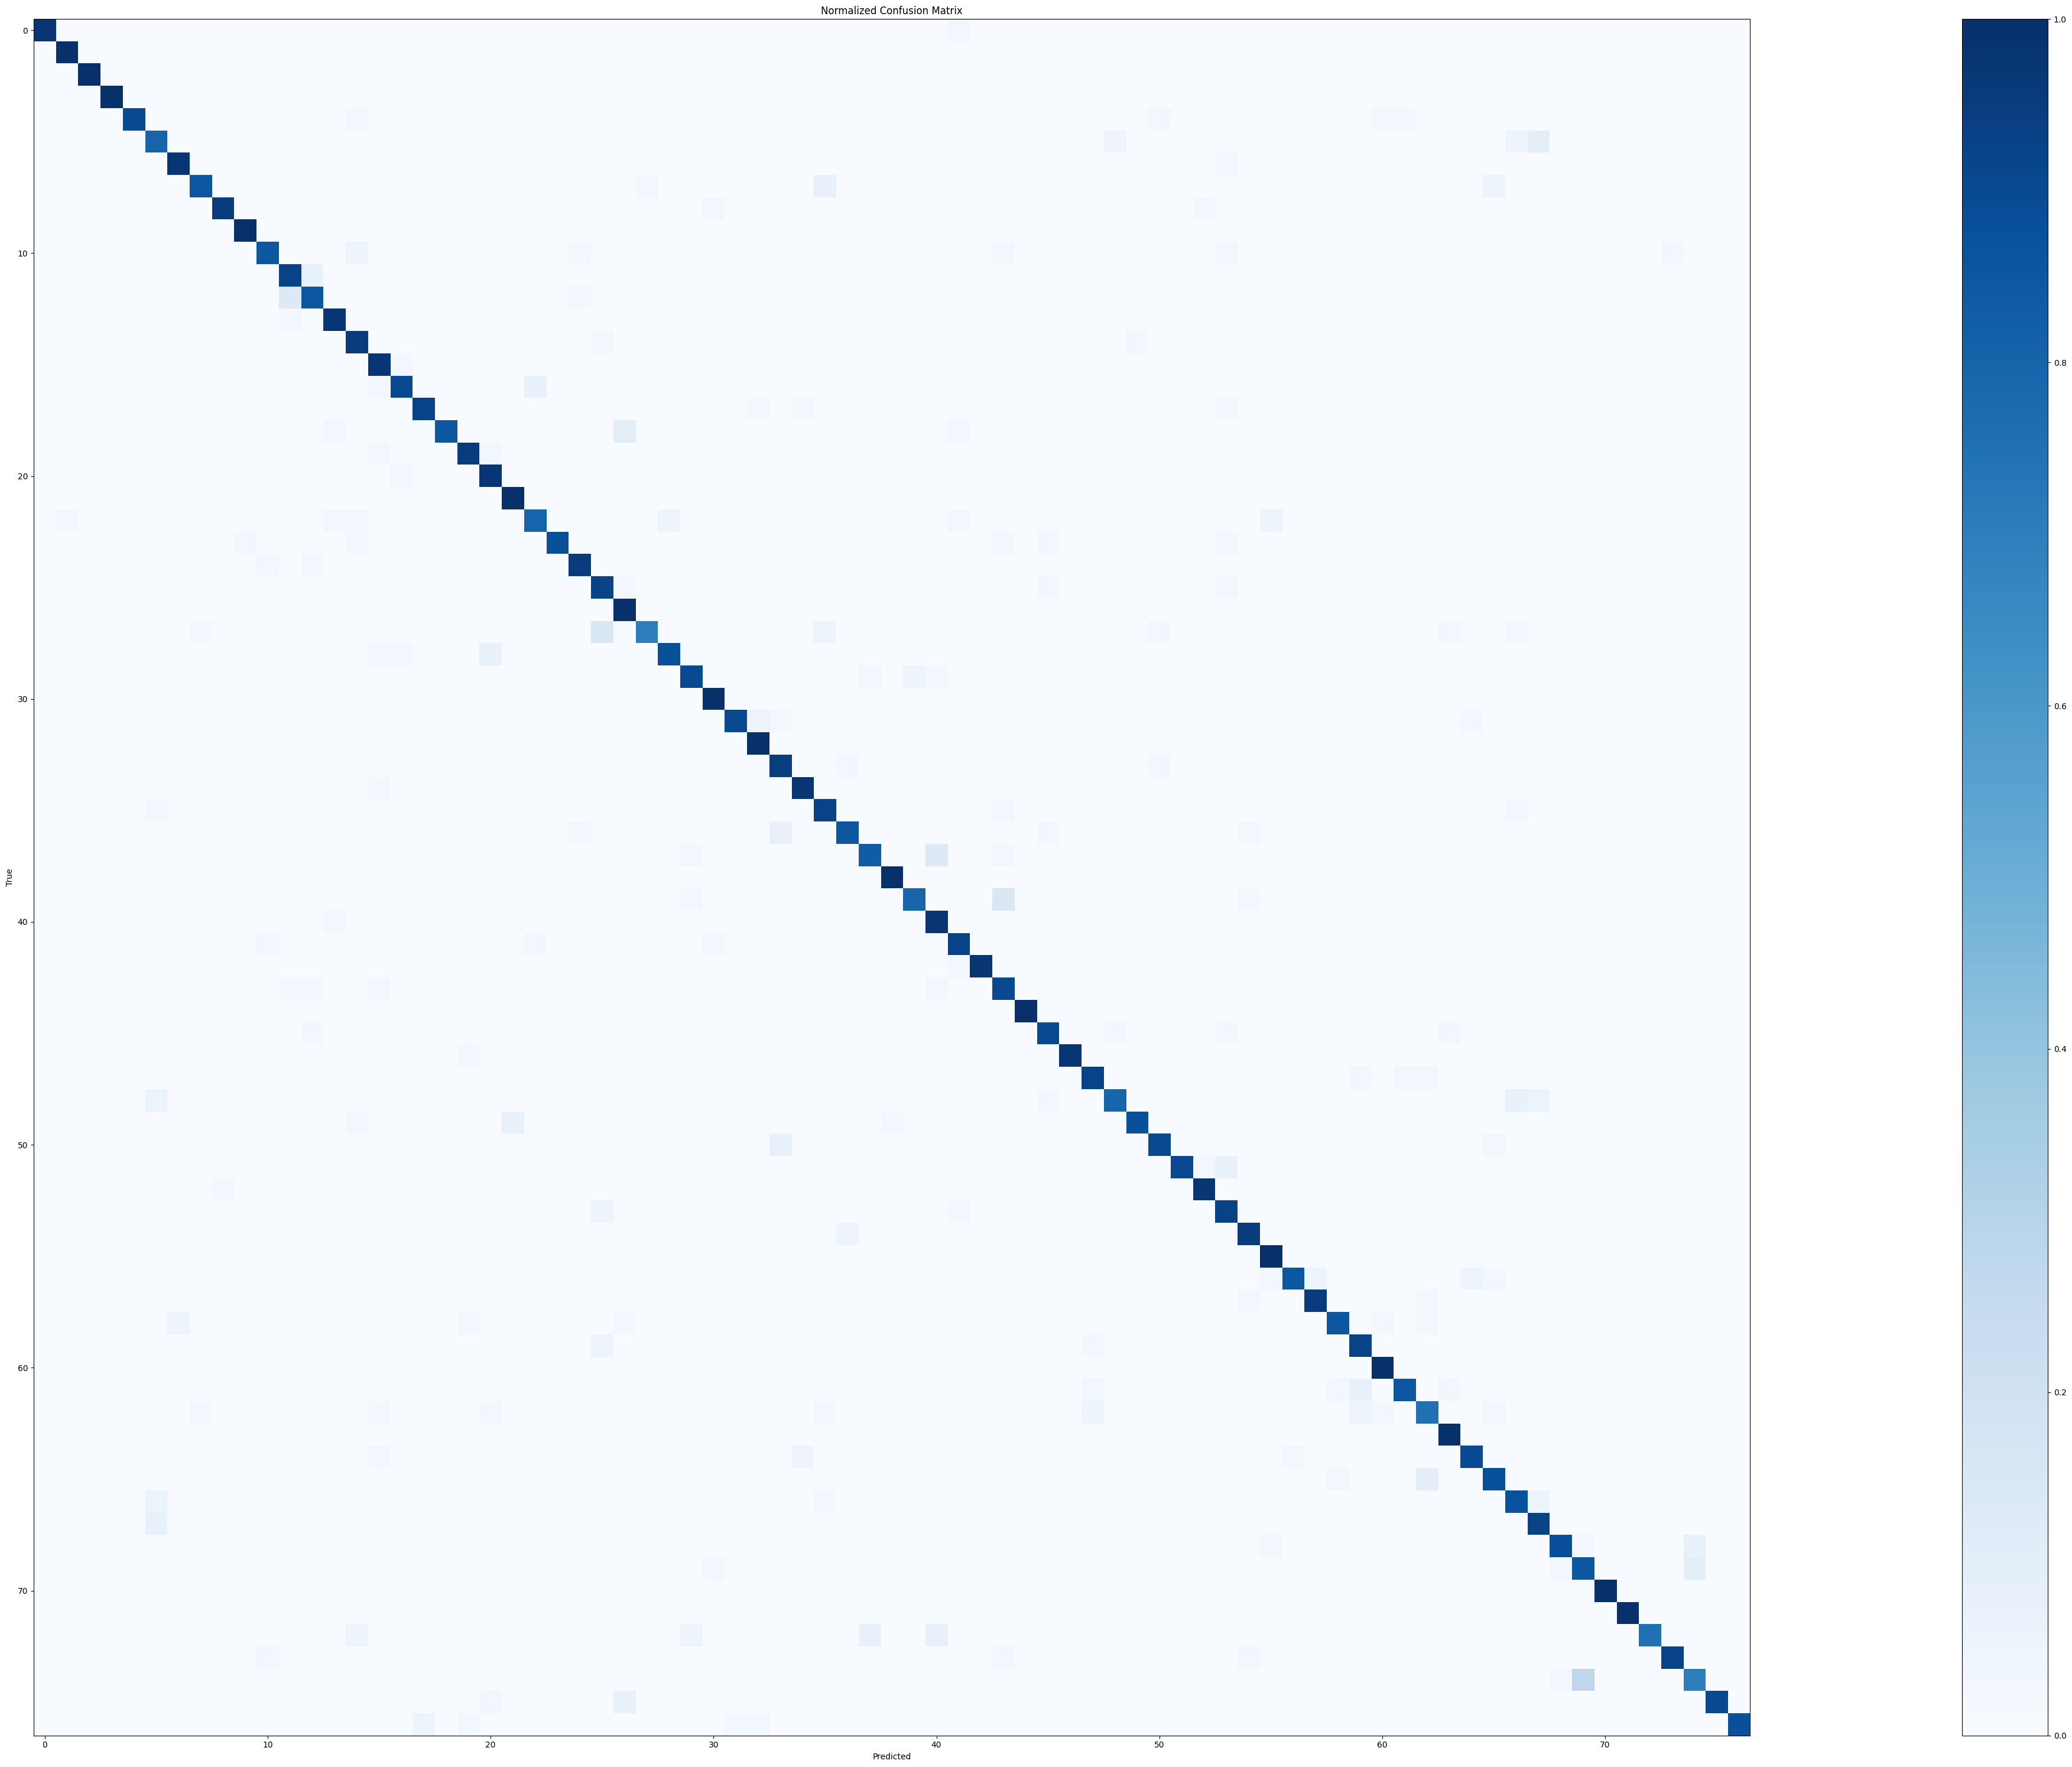

In [20]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(72, 30))
plt.imshow(cm_norm, cmap="Blues")
plt.title("Normalized Confusion Matrix")
plt.colorbar()

plt.xlabel("Predicted")
plt.ylabel("True")

plt.tight_layout()
plt.show()

In [15]:
# # evaluate model

# results = trainer.evaluate()                           
# results = trainer.predict(val_dataset)
# results

In [16]:
from transformers import pipeline
clf = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer)

text = "I am still waiting on my card?"
pred = clf(text)[0]
pred

{'label': 'LABEL_11', 'score': 0.899763822555542}

In [ ]:
import os

print(os.listdir("banking77_trainer"))

In [ ]:
# loss function